# 01 Data audit and exploratory analysis

Coutinho et al. (2026), *Data in Brief* 69, 113341. Jar tests with *Moringa oleifera* seed extract on Jucu River water.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.colors import Normalize
from scipy import stats
from sklearn.ensemble import IsolationForest

from src.config import DATA_PROC, RESULTS, TABLES, KEYS, SED_TIMES, SEED
from src.data import load_raw, add_ids, cell_stats, run_table
from src import style

style.apply()
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)
STATS = RESULTS / "stats"


def rnd(d, n=2):
    return d.round({c: n for c in d.select_dtypes("number").columns})


for p in (DATA_PROC, STATS, TABLES):
    p.mkdir(parents=True, exist_ok=True)

## 1. Load and inspect

In [2]:
raw = load_raw()
print(raw.shape)
raw.head(8)

(3528, 7)


,date,speed,mtime,dose,sed,trial,turb
0,2025-03-24,151,71,100,0,1,223.0
1,2025-03-24,151,71,100,0,2,223.0
2,2025-03-24,151,71,100,0,3,223.0
3,2025-03-24,151,71,100,10,1,186.5
4,2025-03-24,151,71,100,10,2,188.5
5,2025-03-24,151,71,100,10,3,192.7
6,2025-03-24,151,71,100,20,1,125.9
7,2025-03-24,151,71,100,20,2,137.2


In [3]:
for c in ["speed", "mtime", "sed", "trial"]:
    print(f"{c:6s}", sorted(raw[c].unique().tolist()))
print("dose  ", sorted(raw["dose"].unique().tolist()))
print("dates ", raw["date"].nunique(), raw["date"].min().date(), "to", raw["date"].max().date())
raw.drop(columns="date").describe().T.round(2)

speed  [82, 121, 151]
mtime  [71, 120, 150, 200, 250, 300, 309, 450]
sed    [0, 10, 20, 30, 40, 50, 60]
trial  [1, 2, 3]
dose   [40, 50, 60, 65, 70, 80, 85, 90, 95, 100, 110, 115, 120, 125, 130, 140, 145, 150, 160, 170, 175, 180, 190, 200, 225, 250, 300, 350]
dates  22 2025-03-24 to 2026-03-26


,count,mean,std,min,25%,50%,75%,max
speed,3528.0,98.82,25.86,82.0,82.0,82.0,121.00,151.0
mtime,3528.0,236.46,76.04,71.0,237.5,250.0,250.00,450.0
dose,3528.0,169.82,79.45,40.0,100.0,150.0,200.00,350.0
sed,3528.0,30.00,20.00,0.0,10.0,30.0,50.00,60.0
trial,3528.0,2.00,0.82,1.0,1.0,2.0,3.00,3.0
turb,3528.0,60.39,54.94,7.6,25.0,40.0,72.72,293.0


## 2. Missing values, duplicates and value checks

In [4]:
quality = pd.Series({
    "missing cells": int(raw.isna().sum().sum()),
    "exact duplicate rows": int(raw.duplicated().sum()),
    "rows sharing settings, sed and trial": int(raw.duplicated(KEYS + ["sed", "trial"], keep=False).sum()),
    "turbidity <= 0": int((raw["turb"] <= 0).sum()),
    "non-integer settings": int((raw[["speed", "mtime", "dose", "sed", "trial"]] % 1 != 0).sum().sum()),
})
print(raw.isna().sum().to_string(), "\n")
quality

date     0
speed    0
mtime    0
dose     0
sed      0
trial    0
turb     0 



missing cells                            0
exact duplicate rows                     0
rows sharing settings, sed and trial    84
turbidity <= 0                           0
non-integer settings                     0
dtype: int64

Reported turbidity resolution (decimal places) by turbidity range.

In [5]:
def n_decimals(v):
    s = f"{v:.6f}".rstrip("0")
    return len(s.split(".")[1])

raw["dec"] = raw["turb"].map(n_decimals)
display(pd.crosstab(pd.cut(raw["turb"], [0, 10, 100, 1000]), raw["dec"]))
dec_day = pd.crosstab(raw["date"].dt.strftime("%Y-%m-%d"), raw["dec"])
raw = raw.drop(columns="dec")
dec_day.T

dec,0,1,2
turb,,,
"(0, 10]",1,3,19
"(10, 100]",262,2303,423
"(100, 1000]",197,320,0


date,2025-03-24,2025-04-01,2025-04-07,2025-04-09,2025-04-11,2025-09-03,2025-09-08,2025-09-18,2025-09-19,2025-09-22,2025-10-20,2025-10-28,2025-11-05,2025-11-25,2025-12-01,2025-12-08,2026-02-03,2026-02-10,2026-02-12,2026-02-23,2026-03-02,2026-03-26
dec,,,,,,,,,,,,,,,,,,,,,,
0,94,19,12,14,26,8,10,8,7,14,5,9,10,19,13,12,31,12,21,57,30,29
1,284,107,114,112,226,117,93,111,114,68,101,85,130,163,111,90,80,90,82,194,87,67
2,0,0,0,0,0,1,23,7,5,44,20,32,112,70,2,24,15,24,23,1,9,30


## 3. Run and day structure

In [6]:
df = add_ids(raw)
cells = cell_stats(df)
runs = run_table(df)

print(f"{df['run'].nunique()} runs (jars), {runs.groupby(KEYS).ngroups} unique day x setting conditions, "
      f"{df['day'].nunique()} sampling days")
print(f"{runs.groupby(['speed', 'mtime', 'dose']).ngroups} unique speed x mixing time x dose combinations")
print(f"{runs['batch'].nunique()} batches (day x speed x mixing time)")

rep = runs[runs.groupby(KEYS)["run"].transform("size") > 1]
rnd(rep[["run", "date", "speed", "mtime", "dose", "rep_run", "T0", "T60", "rem60"]])

168 runs (jars), 166 unique day x setting conditions, 22 sampling days
99 unique speed x mixing time x dose combinations
25 batches (day x speed x mixing time)


,run,date,speed,mtime,dose,rep_run,T0,T60,rem60
96,96,2025-11-05,82,250,140,1,27.33,11.41,58.27
97,97,2025-11-05,82,250,140,2,26.43,10.77,59.26
106,106,2025-11-25,82,250,100,1,39.43,13.16,66.63
107,107,2025-11-25,82,250,100,2,39.93,12.99,67.47


In [7]:
def levels(s):
    return "/".join(map(str, sorted(s.unique().tolist())))

day_tab = runs.groupby("date").agg(
    day=("day", "first"),
    runs=("run", "size"),
    batches=("batch", "nunique"),
    speed=("speed", levels),
    mtime=("mtime", levels),
    n_doses=("dose", "nunique"),
    dose_min=("dose", "min"),
    dose_max=("dose", "max"),
    T0_mean=("T0", "mean"),
    T0_cv=("T0", lambda s: 100 * s.std() / s.mean()),
    T60_mean=("T60", "mean"),
    rem60_mean=("rem60", "mean"),
)
day_tab.index = day_tab.index.strftime("%Y-%m-%d")
day_tab.round(1).to_csv(TABLES / "table_day_summary.csv")
day_tab.round(1)

,day,runs,batches,speed,mtime,n_doses,dose_min,dose_max,T0_mean,T0_cv,T60_mean,rem60_mean
date,,,,,,,,,,,,
2025-03-24,0,18,3,151,71/120/150,6,100,350,222.9,2.4,52.5,76.5
2025-04-01,1,6,1,151,300,6,100,350,186.4,2.5,43.5,76.7
2025-04-07,2,6,1,121,71,6,100,350,159.6,5.6,90.4,43.8
2025-04-09,3,6,1,121,300,6,100,350,193.8,2.6,37.2,80.9
2025-04-11,4,12,2,121,150/450,6,100,350,167.0,9.7,46.1,72.9
2025-09-03,5,6,1,121,300,6,100,350,118.9,4.1,27.1,77.2
2025-09-08,6,6,1,82,300,6,100,350,92.7,3.0,23.2,75.0
2025-09-18,7,6,1,82,150,6,50,300,91.5,3.4,28.1,69.0
2025-09-19,8,6,1,82,200,6,50,300,95.1,2.6,36.0,62.0


In [8]:
print("days with more than one speed:      ", int((runs.groupby("day")["speed"].nunique() > 1).sum()))
print("days with more than one mixing time:", int((runs.groupby("day")["mtime"].nunique() > 1).sum()))
setting_tab = runs.groupby(["speed", "mtime"]).agg(
    days=("day", "nunique"), runs=("run", "size"),
    dose_min=("dose", "min"), dose_max=("dose", "max"), n_doses=("dose", "nunique"))
setting_tab

days with more than one speed:       0
days with more than one mixing time: 2


days  runs  dose_min  dose_max  n_doses
speed mtime                                         
82    150       1     6        50       300        6
      200       1     6        50       300        6
      250      12    90        40       300       27
      300       1     6       100       350        6
      309       1     6        85       160        6
121   71        1     6       100       350        6
      150       1     6       100       350        6
      300       2    12       100       350        6
      450       1     6       100       350        6
151   71        1     6       100       350        6
      120       1     6       100       350        6
      150       1     6       100       350        6
      300       1     6       100       350        6

figures/eda/fig01_design_map.png


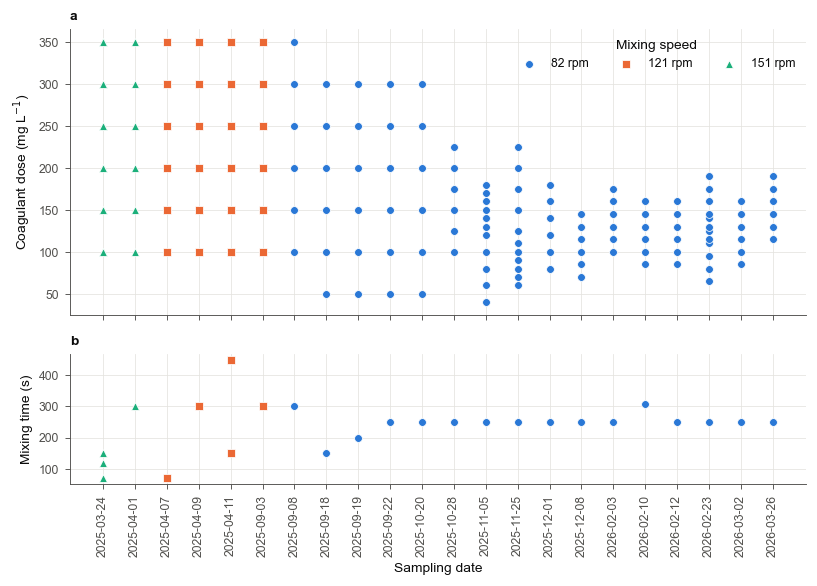

In [9]:
dates = runs.drop_duplicates("day").sort_values("day")
date_lab = dates["date"].dt.strftime("%Y-%m-%d")
speeds = sorted(runs["speed"].unique().tolist())

fig, axes = plt.subplots(2, 1, figsize=(7.5, 5.4), sharex=True, gridspec_kw={"height_ratios": [2.2, 1]})
for i, sp in enumerate(speeds):
    r = runs[runs["speed"] == sp]
    kw = dict(color=style.COLORS[i], marker=style.MARKERS[i], s=26, lw=0.5, ec="white", label=f"{sp} rpm")
    axes[0].scatter(r["day"], r["dose"], **kw)
    rd = r.drop_duplicates(["day", "mtime"])
    axes[1].scatter(rd["day"], rd["mtime"], **kw)
axes[0].set_ylabel("Coagulant dose (mg L$^{-1}$)")
axes[1].set_ylabel("Mixing time (s)")
axes[0].legend(title="Mixing speed", loc="upper right", ncol=3)
axes[1].set_xticks(dates["day"], date_lab, rotation=90)
axes[1].set_xlabel("Sampling date")
style.panel_label(axes[0], "a")
style.panel_label(axes[1], "b")
fig.tight_layout()
print(style.save(fig, "fig01_design_map"))
plt.show()

## 4. Replicate noise

In [11]:
cv_tab = cells.groupby("sed")["cv"].describe(percentiles=[0.5, 0.9]).round(2)
cv_tab["n > 10 %"] = cells.groupby("sed")["cv"].agg(lambda s: int((s > 10).sum()))
cv_tab["n > 20 %"] = cells.groupby("sed")["cv"].agg(lambda s: int((s > 20).sum()))
cv_tab["sd = 0"] = cells.groupby("sed")["sd"].agg(lambda s: int((s == 0).sum()))
cv_tab.to_csv(STATS / "replicate_cv_by_sed.csv")
cv_tab

,count,mean,std,min,50%,90%,max,n > 10 %,n > 20 %,sd = 0
sed,,,,,,,,,,
0,168.0,2.44,2.05,0.00,1.93,4.73,12.99,3,0,1
10,168.0,4.10,2.84,0.22,3.38,7.90,15.22,6,0,0
20,168.0,3.64,2.23,0.25,3.04,6.67,11.58,2,0,0
30,168.0,3.69,2.53,0.22,3.25,7.20,19.69,1,0,0
40,168.0,3.50,2.52,0.15,2.88,6.81,12.23,7,0,0
50,168.0,3.66,2.95,0.00,2.89,7.55,16.03,7,0,1
60,168.0,3.55,2.63,0.13,2.97,7.21,13.08,6,0,0


In [12]:
ok = cells["sd"] > 0
for label, m in [("all times", ok), ("10 to 60 min", ok & (cells["sed"] > 0))]:
    fit = stats.linregress(np.log10(cells.loc[m, "mean"]), np.log10(cells.loc[m, "sd"]))
    print(f"log SD vs log mean, {label}: slope {fit.slope:.2f}, r {fit.rvalue:.2f}, n {m.sum()}")
print(f"cells with SD = 0 excluded: {(~ok).sum()}")

log SD vs log mean, all times: slope 0.63, r 0.53, n 1174
log SD vs log mean, 10 to 60 min: slope 0.64, r 0.46, n 1007
cells with SD = 0 excluded: 2


Systematic trial effect: mean log deviation of each trial from its cell mean (%), Friedman test per settling time.

In [13]:
tr = df.pivot_table(index=["run", "sed"], columns="trial", values="turb")
dev = 100 * np.log(tr.div(tr.mean(axis=1), axis=0))
trial_tab = dev.groupby("sed").mean().round(2)
trial_tab.columns = [f"trial {c} (%)" for c in trial_tab.columns]
trial_tab["friedman p"] = pd.Series(
    {s: stats.friedmanchisquare(*[g[c] for c in g.columns]).pvalue for s, g in tr.groupby("sed")})
trial_tab.loc["10-60"] = list(dev[dev.index.get_level_values("sed") > 0].mean().round(2)) + [
    stats.friedmanchisquare(*[tr.loc[tr.index.get_level_values("sed") > 0, c] for c in tr.columns]).pvalue]
trial_tab.to_csv(STATS / "trial_effect.csv")
trial_tab

,trial 1 (%),trial 2 (%),trial 3 (%),friedman p
sed,,,,
0,-0.46,-0.13,0.49,1.161111e-02
10,2.21,-0.31,-2.14,1.494991e-11
20,1.28,-0.36,-1.11,4.064688e-06
30,1.60,-0.24,-1.56,2.554554e-09
40,1.13,-0.27,-1.05,2.368693e-06
50,0.52,0.28,-1.03,3.656648e-02
60,0.39,-0.30,-0.29,3.718139e-01
10-60,1.19,-0.20,-1.20,4.824591e-27


figures/eda/fig02_replicate_noise.png


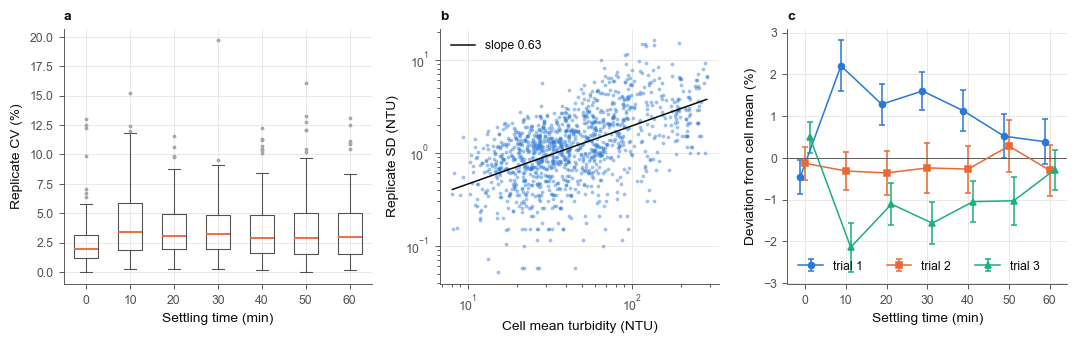

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(10, 3.2), gridspec_kw={"width_ratios": [1.1, 1, 1]})

ax = axes[0]
data = [cells.loc[cells["sed"] == s, "cv"].values for s in SED_TIMES]
ax.boxplot(data, positions=range(len(SED_TIMES)), widths=0.55, showfliers=True,
           medianprops=dict(color=style.COLORS[1], lw=1.2),
           boxprops=dict(color=style.INK2, lw=0.7), whiskerprops=dict(color=style.INK2, lw=0.7),
           capprops=dict(color=style.INK2, lw=0.7),
           flierprops=dict(marker="o", ms=2.5, mfc=style.MUTED, mec="none"))
ax.set_xticks(range(len(SED_TIMES)), SED_TIMES)
ax.set_xlabel("Settling time (min)")
ax.set_ylabel("Replicate CV (%)")
style.panel_label(ax, "a")

ax = axes[1]
m = cells["sd"] > 0
ax.scatter(cells.loc[m, "mean"], cells.loc[m, "sd"], s=6, color=style.COLORS[0], alpha=0.45, lw=0)
fit = stats.linregress(np.log10(cells.loc[m, "mean"]), np.log10(cells.loc[m, "sd"]))
xx = np.geomspace(cells["mean"].min(), cells["mean"].max(), 50)
ax.plot(xx, 10 ** fit.intercept * xx ** fit.slope, color=style.INK, lw=1, label=f"slope {fit.slope:.2f}")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("Cell mean turbidity (NTU)")
ax.set_ylabel("Replicate SD (NTU)")
ax.legend(loc="upper left")
style.panel_label(ax, "b")

ax = axes[2]
d = dev.reset_index().melt(id_vars=["run", "sed"], var_name="trial", value_name="dev")
for i, t in enumerate(sorted(d["trial"].unique())):
    g = d[d["trial"] == t].groupby("sed")["dev"]
    mu, se = g.mean(), g.sem()
    x = np.arange(len(SED_TIMES)) + (i - 1) * 0.12
    ax.errorbar(x, mu.values, yerr=1.96 * se.values, color=style.COLORS[i], marker=style.MARKERS[i],
                ms=4, lw=1, capsize=2, label=f"trial {t}")
ax.axhline(0, color=style.INK2, lw=0.6)
ax.set_xticks(range(len(SED_TIMES)), SED_TIMES)
ax.set_xlabel("Settling time (min)")
ax.set_ylabel("Deviation from cell mean (%)")
ax.legend(loc="lower left", ncol=3)
style.panel_label(ax, "c")

fig.tight_layout()
print(style.save(fig, "fig02_replicate_noise"))
plt.show()

Noise ceiling: best R² any model could reach given replicate scatter, for single replicates and for triplicate means.

In [15]:
def ceiling(y, cell):
    pooled = y.groupby(cell).var(ddof=1).mean()
    means = y.groupby(cell).mean()
    return 1 - pooled / y.var(ddof=1), 1 - (pooled / 3) / means.var(ddof=1)

d = df.assign(log_turb=np.log10(df["turb"]))
rows = {}
for s in SED_TIMES[1:]:
    g = d[d["sed"] == s]
    for var in ["turb", "log_turb", "removal"]:
        rows[(s, var)] = ceiling(g[var], g["run"])
g = d[d["sed"] > 0]
for var in ["turb", "log_turb", "removal"]:
    rows[("10-60", var)] = ceiling(g[var], g["run"].astype(str) + "_" + g["sed"].astype(str))
noise = pd.DataFrame(rows, index=["R2_max_replicate", "R2_max_mean"]).T.unstack().round(4)
noise.to_csv(STATS / "noise_ceiling.csv")
noise

R2_max_replicate                 R2_max_mean                
              log_turb removal    turb    log_turb removal    turb
10              0.9914  0.9868  0.9890      0.9971  0.9956  0.9963
20              0.9924  0.9930  0.9934      0.9975  0.9977  0.9978
30              0.9919  0.9930  0.9955      0.9973  0.9977  0.9985
40              0.9934  0.9921  0.9970      0.9978  0.9974  0.9990
50              0.9932  0.9924  0.9977      0.9977  0.9975  0.9992
60              0.9945  0.9943  0.9978      0.9982  0.9981  0.9993
10-60           0.9951  0.9938  0.9951      0.9983  0.9979  0.9984

## 5. Distributions

In [16]:
skew = pd.DataFrame({
    "skew raw": df.groupby("sed")["turb"].agg(stats.skew),
    "skew log10": df.groupby("sed")["turb"].agg(lambda s: stats.skew(np.log10(s))),
    "median": df.groupby("sed")["turb"].median(),
    "min": df.groupby("sed")["turb"].min(),
    "max": df.groupby("sed")["turb"].max(),
})
skew.loc["all"] = [stats.skew(df["turb"]), stats.skew(np.log10(df["turb"])),
                   df["turb"].median(), df["turb"].min(), df["turb"].max()]
skew.round(2)

,skew raw,skew log10,median,min,max
sed,,,,,
0,-0.02,-0.64,154.80,23.90,293.0
10,0.87,-0.13,68.90,23.20,213.0
20,1.21,0.27,45.90,19.31,161.7
30,1.56,0.46,35.50,14.76,147.0
40,1.73,0.47,29.10,10.38,136.3
50,1.90,0.45,25.45,7.82,129.5
60,1.97,0.43,22.80,7.60,121.5
all,1.97,0.40,40.00,7.60,293.0


figures/eda/fig03_distributions.png


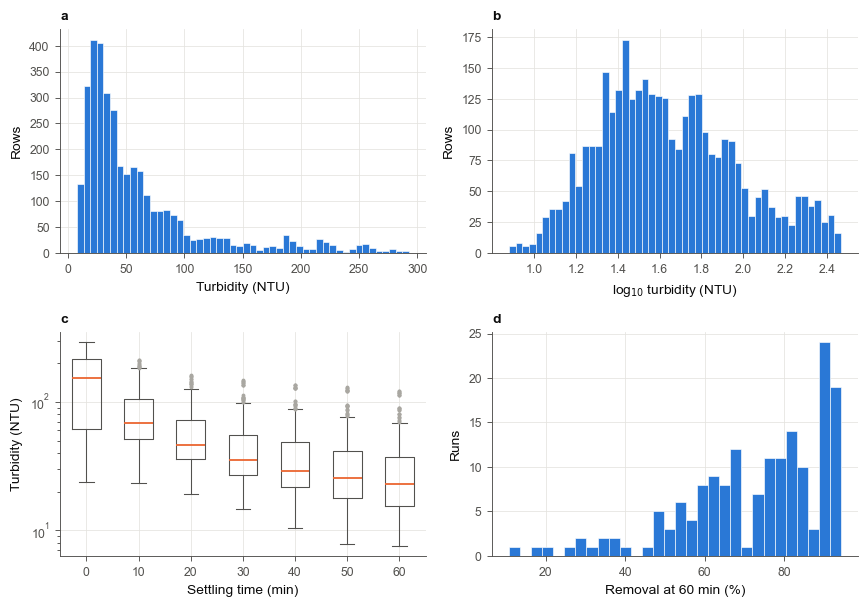

In [17]:
fig, axes = plt.subplots(2, 2, figsize=(8, 5.6))
hist_kw = dict(color=style.COLORS[0], edgecolor="white", lw=0.4)

axes[0, 0].hist(df["turb"], bins=50, **hist_kw)
axes[0, 0].set_xlabel("Turbidity (NTU)")
axes[0, 0].set_ylabel("Rows")
style.panel_label(axes[0, 0], "a")

axes[0, 1].hist(np.log10(df["turb"]), bins=50, **hist_kw)
axes[0, 1].set_xlabel("log$_{10}$ turbidity (NTU)")
axes[0, 1].set_ylabel("Rows")
style.panel_label(axes[0, 1], "b")

ax = axes[1, 0]
ax.boxplot([df.loc[df["sed"] == s, "turb"] for s in SED_TIMES], positions=range(len(SED_TIMES)), widths=0.55,
           medianprops=dict(color=style.COLORS[1], lw=1.2), boxprops=dict(color=style.INK2, lw=0.7),
           whiskerprops=dict(color=style.INK2, lw=0.7), capprops=dict(color=style.INK2, lw=0.7),
           flierprops=dict(marker="o", ms=2.5, mfc=style.MUTED, mec="none"))
ax.set_yscale("log")
ax.set_xticks(range(len(SED_TIMES)), SED_TIMES)
ax.set_xlabel("Settling time (min)")
ax.set_ylabel("Turbidity (NTU)")
style.panel_label(ax, "c")

axes[1, 1].hist(runs["rem60"], bins=30, **hist_kw)
axes[1, 1].set_xlabel("Removal at 60 min (%)")
axes[1, 1].set_ylabel("Runs")
style.panel_label(axes[1, 1], "d")

fig.tight_layout()
print(style.save(fig, "fig03_distributions"))
plt.show()

## 6. Initial turbidity by day

In [18]:
t0_day = runs.groupby("date")["T0"].agg(["size", "mean", "min", "max", "std"])
t0_day["cv %"] = 100 * t0_day["std"] / t0_day["mean"]
t0_day["range %"] = 100 * (t0_day["max"] - t0_day["min"]) / t0_day["mean"]
t0_day["rho(dose, T0)"] = pd.Series(
    {d: stats.spearmanr(g["dose"], g["T0"]).statistic for d, g in runs.groupby("date") if g["dose"].nunique() > 2})
t0_day.index = t0_day.index.strftime("%Y-%m-%d")
print(f"within-day Spearman rho(dose, T0): median {t0_day['rho(dose, T0)'].median():.2f}, "
      f"range {t0_day['rho(dose, T0)'].min():.2f} to {t0_day['rho(dose, T0)'].max():.2f}")
t0_day.round(2)

within-day Spearman rho(dose, T0): median 0.17, range -1.00 to 0.94


,size,mean,min,max,std,cv %,range %,"rho(dose, T0)"
date,,,,,,,,
2025-03-24,18,222.89,212.00,232.67,5.27,2.36,9.27,0.19
2025-04-01,6,186.41,180.77,194.43,4.74,2.54,7.33,0.26
2025-04-07,6,159.62,147.50,172.27,8.95,5.61,15.52,0.54
2025-04-09,6,193.83,186.13,199.13,5.11,2.64,6.71,0.94
2025-04-11,12,166.98,146.63,188.03,16.21,9.71,24.79,0.47
2025-09-03,6,118.89,112.90,124.23,4.85,4.08,9.53,0.77
2025-09-08,6,92.74,88.93,97.33,2.79,3.01,9.06,-0.14
2025-09-18,6,91.51,86.63,94.70,3.15,3.44,8.82,-1.00
2025-09-19,6,95.14,90.60,97.27,2.46,2.58,7.01,-0.26


figures/eda/fig04_t0_removal_by_day.png


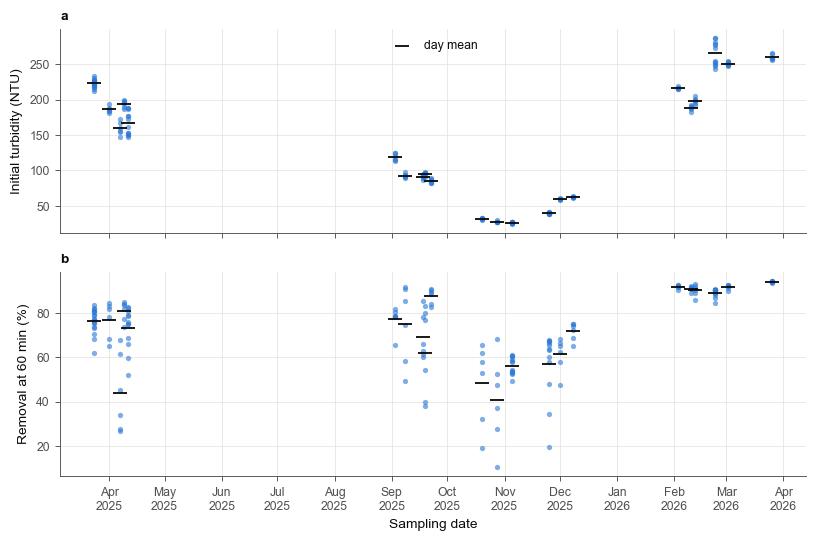

In [19]:
fig, axes = plt.subplots(2, 1, figsize=(7.5, 5), sharex=True)
for ax, col, lab in [(axes[0], "T0", "Initial turbidity (NTU)"), (axes[1], "rem60", "Removal at 60 min (%)")]:
    ax.scatter(runs["date"], runs[col], s=12, color=style.COLORS[0], alpha=0.6, lw=0)
    mu = runs.groupby("date")[col].mean()
    ax.scatter(mu.index, mu.values, color=style.INK, marker="_", s=90, lw=1.2, label="day mean")
    ax.set_ylabel(lab)
axes[1].xaxis.set_major_locator(mdates.MonthLocator())
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%b\n%Y"))
axes[1].set_xlabel("Sampling date")
axes[0].legend(loc="upper center")
style.panel_label(axes[0], "a")
style.panel_label(axes[1], "b")
fig.tight_layout()
print(style.save(fig, "fig04_t0_removal_by_day"))
plt.show()

## 7. Settling curves

figures/eda/fig05_settling_curves_by_day.png


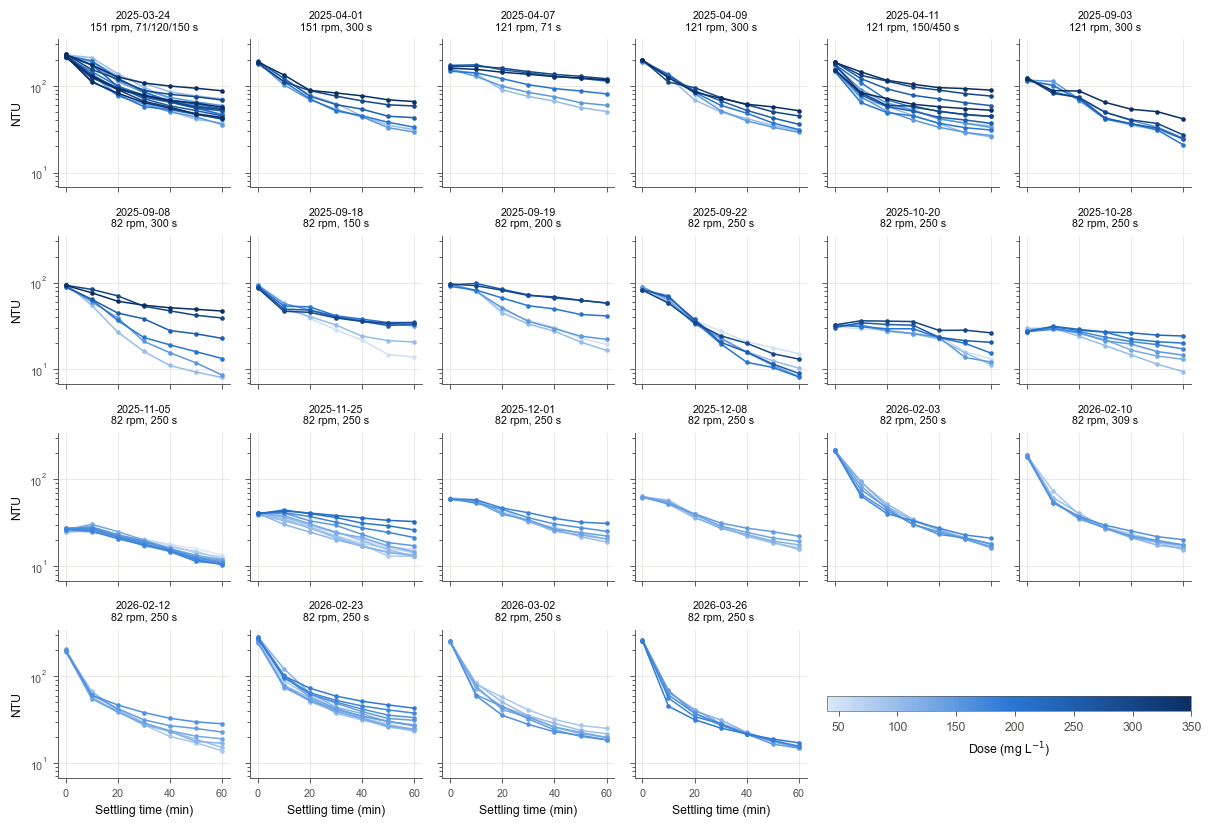

In [20]:
norm = Normalize(runs["dose"].min(), runs["dose"].max())
mean_curves = cells.pivot(index="run", columns="sed", values="mean")
fig, axes = plt.subplots(4, 6, figsize=(11, 7.6), sharex=True, sharey=True)
axes = axes.ravel()
for ax, (day, g) in zip(axes, runs.groupby("day")):
    for _, r in g.sort_values("dose").iterrows():
        ax.plot(SED_TIMES, mean_curves.loc[r["run"]], color=style.SEQ(norm(r["dose"])), lw=1, marker="o", ms=2)
    ax.set_title(f"{g['date'].iloc[0]:%Y-%m-%d}\n{levels(g['speed'])} rpm, {levels(g['mtime'])} s", fontsize=7)
    ax.set_yscale("log")
    ax.tick_params(labelsize=7)
for ax in axes[len(runs["day"].unique()):]:
    ax.axis("off")
for ax in axes[::6]:
    ax.set_ylabel("NTU", fontsize=8)
for ax in axes[18:24]:
    ax.set_xlabel("Settling time (min)", fontsize=8)
    ax.set_xticks([0, 20, 40, 60])
fig.tight_layout()
p0, p1 = axes[22].get_position(), axes[23].get_position()
cax = fig.add_axes([p0.x0, p0.y0 + p0.height * 0.45, p1.x1 - p0.x0, p0.height * 0.1])
cb = fig.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=style.SEQ), cax=cax, orientation="horizontal")
cb.set_label("Dose (mg L$^{-1}$)", fontsize=8)
cb.outline.set_linewidth(0.4)
print(style.save(fig, "fig05_settling_curves_by_day"))
plt.show()

In [21]:
norm_curves = mean_curves.div(mean_curves[0], axis=0)
frac = (-mean_curves).add(mean_curves[0], axis=0).div(mean_curves[0] - mean_curves[60], axis=0)

summary = pd.DataFrame({
    "T/T0 median": norm_curves.median(),
    "T/T0 q10": norm_curves.quantile(0.1),
    "T/T0 q90": norm_curves.quantile(0.9),
    "share of 60-min removal, median": frac.median(),
    "runs with T > T0": (norm_curves > 1).sum(),
})
summary.round(3)

,T/T0 median,T/T0 q10,T/T0 q90,"share of 60-min removal, median",runs with T > T0
sed,,,,,
0,1.000,1.000,1.000,0.000,0
10,0.697,0.299,1.011,0.394,22
20,0.475,0.201,0.879,0.689,7
30,0.365,0.144,0.771,0.840,2
40,0.307,0.116,0.677,0.911,0
50,0.266,0.096,0.573,0.964,0
60,0.230,0.083,0.506,1.000,0


figures/eda/fig06_normalised_curves.png


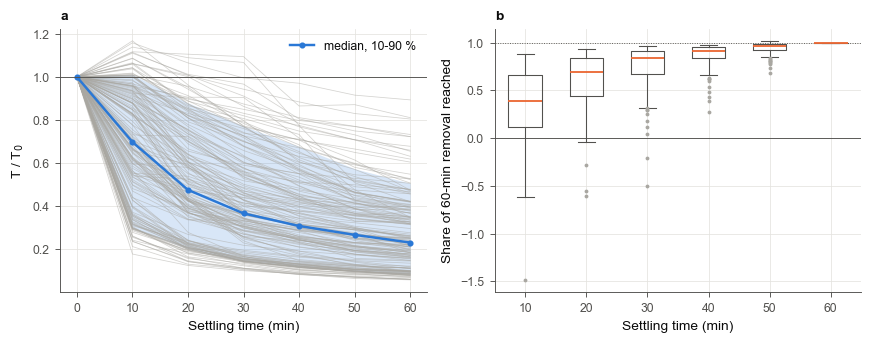

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(8, 3.2))
ax = axes[0]
for run, row in norm_curves.iterrows():
    ax.plot(SED_TIMES, row.values, color=style.MUTED, lw=0.5, alpha=0.5)
ax.fill_between(SED_TIMES, norm_curves.quantile(0.1), norm_curves.quantile(0.9), color=style.COLORS[0], alpha=0.18, lw=0)
ax.plot(SED_TIMES, norm_curves.median(), color=style.COLORS[0], lw=1.6, marker="o", ms=3, label="median, 10-90 %")
ax.axhline(1, color=style.INK2, lw=0.6)
ax.set_xlabel("Settling time (min)")
ax.set_ylabel("T / T$_0$")
ax.legend(loc="upper right")
style.panel_label(ax, "a")

ax = axes[1]
ax.boxplot([frac[s].values for s in SED_TIMES[1:]], positions=range(len(SED_TIMES) - 1), widths=0.55,
           medianprops=dict(color=style.COLORS[1], lw=1.2), boxprops=dict(color=style.INK2, lw=0.7),
           whiskerprops=dict(color=style.INK2, lw=0.7), capprops=dict(color=style.INK2, lw=0.7),
           flierprops=dict(marker="o", ms=2.5, mfc=style.MUTED, mec="none"))
ax.set_xticks(range(len(SED_TIMES) - 1), SED_TIMES[1:])
ax.axhline(0, color=style.INK2, lw=0.6)
ax.axhline(1, color=style.INK2, lw=0.6, ls=":")
ax.set_xlabel("Settling time (min)")
ax.set_ylabel("Share of 60-min removal reached")
style.panel_label(ax, "b")
fig.tight_layout()
print(style.save(fig, "fig06_normalised_curves"))
plt.show()

## 8. Non-monotone curves

Rises between consecutive settling times in triplicate means, compared with the standard error of the difference.

In [23]:
sd_curves = cells.pivot(index="run", columns="sed", values="sd")
rows = []
for a, b in zip(SED_TIMES[:-1], SED_TIMES[1:]):
    diff = mean_curves[b] - mean_curves[a]
    se = np.sqrt((sd_curves[a] ** 2 + sd_curves[b] ** 2) / 3)
    for run in diff.index[diff > 0]:
        rows.append(dict(run=run, interval=f"{a}-{b}", rise=diff[run],
                         rise_pct=100 * diff[run] / mean_curves.loc[run, a],
                         z=diff[run] / se[run] if se[run] > 0 else np.inf))
rises = pd.DataFrame(rows).join(runs.set_index("run")[["date", "speed", "mtime", "dose"]], on="run")
rises["z>2"] = rises["z"] > 2

print(f"runs with any rise: {rises['run'].nunique()} of {len(runs)}")
print(f"runs with a rise after 10 min: {rises.loc[rises['interval'] != '0-10', 'run'].nunique()}")
print(f"runs with a rise with z > 2: {rises.loc[rises['z>2'], 'run'].nunique()}")
display(rises.groupby("interval").agg(n=("run", "size"), z_gt_2=("z>2", "sum"),
                                       median_rise_pct=("rise_pct", "median"), max_rise_pct=("rise_pct", "max")).round(2))
rises.to_csv(STATS / "rising_steps.csv", index=False)

runs with any rise: 25 of 168
runs with a rise after 10 min: 4
runs with a rise with z > 2: 11


,n,z_gt_2,median_rise_pct,max_rise_pct
interval,,,,
0-10,22,10,6.05,16.77
40-50,1,0,0.71,0.71
50-60,3,1,1.77,3.54


In [24]:
by_day = rises.groupby(rises["date"].dt.strftime("%Y-%m-%d")).agg(
    runs_with_rise=("run", "nunique"), steps=("run", "size"), z_gt_2=("z>2", "sum"))
by_day["runs_that_day"] = runs.groupby(runs["date"].dt.strftime("%Y-%m-%d")).size()
display(by_day)
rnd(rises.sort_values("z", ascending=False).head(15))

,runs_with_rise,steps,z_gt_2,runs_that_day
date,,,,
2025-04-07,2,2,0,6
2025-09-18,3,3,1,6
2025-09-19,1,1,0,6
2025-10-20,3,4,2,6
2025-10-28,6,6,4,6
2025-11-05,6,6,2,12
2025-11-25,4,4,2,12


,run,interval,rise,rise_pct,z,date,speed,mtime,dose,z>2
11,89,0-10,4.30,15.85,5.60,2025-10-28,82,250,225,True
5,83,0-10,3.80,11.68,5.43,2025-10-20,82,250,300,True
10,88,0-10,3.07,11.03,4.47,2025-10-28,82,250,200,True
21,113,0-10,2.53,6.22,4.03,2025-11-25,82,250,225,True
14,95,0-10,4.37,16.77,3.66,2025-11-05,82,250,130,True
8,86,0-10,2.37,8.55,3.48,2025-10-28,82,250,150,True
4,82,0-10,4.20,13.88,3.30,2025-10-20,82,250,250,True
7,85,0-10,2.40,8.73,2.55,2025-10-28,82,250,125,True
12,92,0-10,0.97,3.73,2.41,2025-11-05,82,250,80,True
20,112,0-10,4.57,11.42,2.31,2025-11-25,82,250,200,True


## 9. Dose response and overdosing

In [25]:
rep_sd60 = df[df["sed"] == 60].groupby("run")["removal"].std()
pooled_sd60 = np.sqrt((rep_sd60 ** 2).mean())
print(f"pooled replicate SD of removal at 60 min: {pooled_sd60:.2f} percentage points")

rows = []
for day, g in runs.groupby("day"):
    g = g.groupby("dose", as_index=False)[["rem60", "T60"]].mean()
    i = g["rem60"].idxmax()
    rows.append(dict(
        date=f"{runs.loc[runs['day'] == day, 'date'].iloc[0]:%Y-%m-%d}",
        n_doses=len(g), dose_min=g["dose"].min(), dose_max=g["dose"].max(),
        best_dose=g.loc[i, "dose"], best_rem60=g.loc[i, "rem60"],
        best_at_edge=g.loc[i, "dose"] in (g["dose"].min(), g["dose"].max()),
        drop_to_max_dose=g.loc[i, "rem60"] - g["rem60"].iloc[-1],
        rho_dose_rem60=stats.spearmanr(g["dose"], g["rem60"]).statistic if len(g) > 2 else np.nan,
    ))
best = pd.DataFrame(rows)
best["drop_over_noise"] = best["drop_to_max_dose"] / (pooled_sd60 * np.sqrt(2 / 3))
best.round(2).to_csv(STATS / "best_dose_by_day.csv", index=False)
print("best dose at the low edge:", int((best["best_at_edge"] & (best["best_dose"] == best["dose_min"])).sum()),
      "| high edge:", int((best["best_at_edge"] & (best["best_dose"] == best["dose_max"])).sum()),
      "| interior:", int((~best["best_at_edge"]).sum()))
best.round(2)

pooled replicate SD of removal at 60 min: 1.35 percentage points
best dose at the low edge: 5 | high edge: 1 | interior: 16


,date,n_doses,dose_min,dose_max,best_dose,best_rem60,best_at_edge,drop_to_max_dose,rho_dose_rem60,drop_over_noise
0,2025-03-24,6,100,350,150,78.62,False,6.49,-0.66,5.87
1,2025-04-01,6,100,350,150,84.35,False,19.30,-0.94,17.45
2,2025-04-07,6,100,350,100,67.59,True,40.81,-1.00,36.90
3,2025-04-09,6,100,350,150,84.67,False,10.84,-0.83,9.80
4,2025-04-11,6,100,350,150,81.59,False,22.61,-0.94,20.45
5,2025-09-03,6,100,350,200,81.91,False,16.34,-0.49,14.77
6,2025-09-08,6,100,350,100,91.71,True,42.23,-1.00,38.19
7,2025-09-18,6,50,300,50,85.34,True,25.16,-0.94,22.75
8,2025-09-19,6,50,300,100,83.03,False,43.42,-0.89,39.26
9,2025-09-22,6,50,300,150,90.76,False,6.80,0.20,6.15


figures/eda/fig07_dose_response_by_day.png


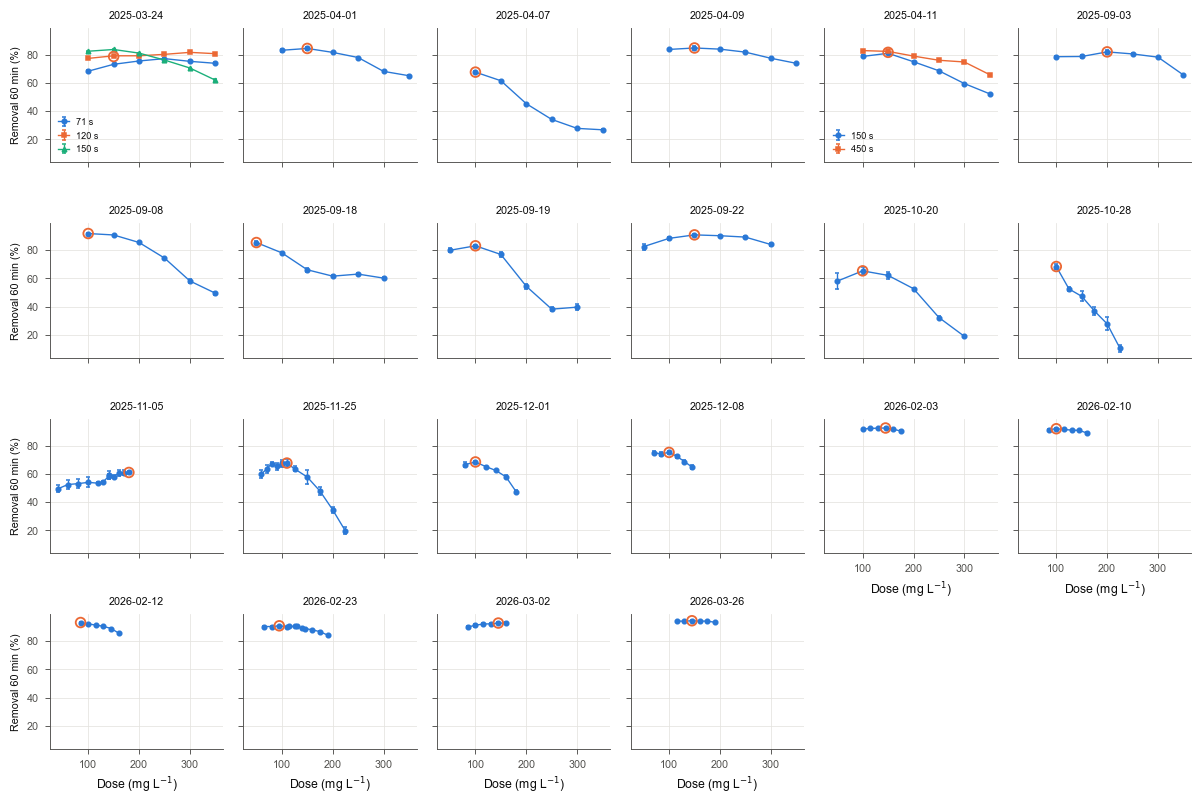

In [26]:
tr60 = df[df["sed"] == 60].groupby("run")["removal"].agg(["mean", "std"])
fig, axes = plt.subplots(4, 6, figsize=(11, 7.4), sharex=True, sharey=True)
axes = axes.ravel()
for ax, (day, g) in zip(axes, runs.groupby("day")):
    for j, (bt, gb) in enumerate(g.groupby("batch")):
        gb = gb.sort_values(["dose", "rep_run"])
        e = tr60.loc[gb["run"]]
        lab = f"{gb['mtime'].iloc[0]} s" if g["batch"].nunique() > 1 else None
        ax.errorbar(gb["dose"], e["mean"], yerr=e["std"], color=style.COLORS[j], marker=style.MARKERS[j],
                    ms=3, lw=0.9, capsize=1.5, label=lab)
    if g["batch"].nunique() > 1:
        ax.legend(loc="lower left", fontsize=6, handlelength=1.2)
    b = best.iloc[day]
    ax.scatter([b["best_dose"]], [b["best_rem60"]], s=40, facecolor="none", edgecolor=style.COLORS[1], lw=1.2, zorder=3)
    ax.set_title(f"{g['date'].iloc[0]:%Y-%m-%d}", fontsize=7)
    ax.tick_params(labelsize=7)
for ax in axes[len(best):]:
    ax.axis("off")
for ax in axes[::6]:
    ax.set_ylabel("Removal 60 min (%)", fontsize=7)
for ax in axes[16:22]:
    ax.set_xlabel("Dose (mg L$^{-1}$)", fontsize=8)
    ax.xaxis.set_tick_params(labelbottom=True)
fig.tight_layout()
print(style.save(fig, "fig07_dose_response_by_day"))
plt.show()

## 10. Outliers

Global IQR rule per settling time, on raw and log turbidity.

In [27]:
def iqr_flag(s, k=1.5):
    q1, q3 = s.quantile([0.25, 0.75])
    return (s < q1 - k * (q3 - q1)) | (s > q3 + k * (q3 - q1))

df["iqr_raw"] = df.groupby("sed")["turb"].transform(iqr_flag)
df["iqr_log"] = df.groupby("sed")["turb"].transform(lambda s: iqr_flag(np.log10(s)))
print("rows flagged, raw:", int(df["iqr_raw"].sum()), "| log:", int(df["iqr_log"].sum()))
pd.crosstab(df.loc[df["iqr_raw"], "date"].dt.strftime("%Y-%m-%d"), df.loc[df["iqr_raw"], "sed"])

rows flagged, raw: 116 | log: 0


sed,10,20,30,40,50,60
date,,,,,,
2025-03-24,12,6,6,3,5,6
2025-04-07,0,9,12,12,12,12
2025-04-11,0,0,3,6,6,6


Replicate-level: standardised residual of each trial from its cell mean in log space, pooled SD per settling time.

In [28]:
lt = np.log10(df["turb"])
res = lt - lt.groupby([df["run"], df["sed"]]).transform("mean")
ss = (res ** 2).groupby(df["sed"]).sum()
n = res.groupby(df["sed"]).size()
pooled_sd = np.sqrt(ss / (n * 2 / 3))
df["rep_z"] = res / (df["sed"].map(pooled_sd) * np.sqrt(2 / 3))
print("pooled replicate SD of log10 turbidity by settling time:")
print(pooled_sd.round(4).to_string())
print(f"\n|z| > 3.5: {int((df['rep_z'].abs() > 3.5).sum())} rows, |z| > 5: {int((df['rep_z'].abs() > 5).sum())} rows")
rnd(df.loc[df["rep_z"].abs() > 3.5, ["run", "date", "dose", "sed", "trial", "turb", "rep_z"]].sort_values(
    "rep_z", key=abs, ascending=False))

pooled replicate SD of log10 turbidity by settling time:
sed
0     0.0139
10    0.0217
20    0.0186
30    0.0195
40    0.0188
50    0.0205
60    0.0192

|z| > 3.5: 26 rows, |z| > 5: 4 rows


,run,date,dose,sed,trial,turb,rep_z
1270,60,2025-09-18,50,30,2,22.70,-5.84
1050,50,2025-09-03,200,0,1,98.60,-5.62
1271,60,2025-09-18,50,30,3,33.90,5.10
1114,53,2025-09-03,350,0,2,105.10,-5.07
1178,56,2025-09-08,200,0,3,103.20,4.93
1176,56,2025-09-08,200,0,1,80.60,-4.51
1155,55,2025-09-08,150,0,1,82.00,-4.41
1115,53,2025-09-03,350,0,3,134.60,4.38
1052,50,2025-09-03,200,0,3,127.90,4.32
1656,78,2025-10-20,50,60,1,11.25,-4.30


Run-level: jar initial turbidity against its batch median (robust z on log ratio). Day-median version for comparison.

In [29]:
def robust_z(x):
    return x / stats.median_abs_deviation(x, scale="normal")

lr_day = np.log10(runs["T0"] / runs.groupby("day")["T0"].transform("median"))
runs["t0_logratio"] = np.log10(runs["T0"] / runs.groupby("batch")["T0"].transform("median"))
runs["t0_z"] = robust_z(runs["t0_logratio"])
print("flagged |z| > 3.5, day median:", int((robust_z(lr_day).abs() > 3.5).sum()),
      "| batch median:", int((runs["t0_z"].abs() > 3.5).sum()))
rnd(runs.loc[runs["t0_z"].abs() > 3.5, ["run", "date", "mtime", "dose", "T0", "t0_logratio", "t0_z"]], 3)

flagged |z| > 3.5, day median: 7 | batch median: 5


,run,date,mtime,dose,T0,t0_logratio,t0_z
27,27,2025-04-07,71,250,172.267,0.038,3.777
36,36,2025-04-11,150,100,161.800,-0.050,-5.061
46,46,2025-04-11,450,300,176.367,0.066,6.598
148,148,2026-02-23,250,115,286.667,0.037,3.732
150,150,2026-02-23,250,130,286.333,0.037,3.681


Multivariate: Isolation Forest on run-level features, top 5 %. It flags extremes of the design space as well as errors.

In [30]:
feat = pd.DataFrame({
    "log_T0": np.log10(runs["T0"]), "dose": runs["dose"],
    "log_T60": np.log10(runs["T60"]), "T30_T0": runs["T30"] / runs["T0"], "rem60": runs["rem60"],
})
iso = IsolationForest(n_estimators=500, contamination=0.05, random_state=SEED).fit(feat)
runs["iso_score"] = -iso.score_samples(feat)
runs["iso_flag"] = iso.predict(feat) == -1
print("runs flagged:", int(runs["iso_flag"].sum()))
rnd(runs.loc[runs["iso_flag"], ["run", "date", "dose", "T0", "T60", "rem60", "iso_score"]].sort_values(
    "iso_score", ascending=False))

runs flagged: 9


,run,date,dose,T0,T60,rem60,iso_score
83,83,2025-10-20,300,32.53,26.37,18.95,0.66
29,29,2025-04-07,350,160.07,117.20,26.78,0.65
89,89,2025-10-28,225,27.13,24.23,10.69,0.64
28,28,2025-04-07,300,167.13,120.70,27.78,0.63
113,113,2025-11-25,225,40.70,32.73,19.57,0.61
27,27,2025-04-07,250,172.27,113.50,34.11,0.61
82,82,2025-10-20,250,30.27,20.50,32.27,0.61
41,41,2025-04-11,350,186.63,89.20,52.21,0.57
26,26,2025-04-07,200,147.50,80.77,45.24,0.57


In [31]:
flags = runs.set_index("run")[["date", "speed", "mtime", "dose", "t0_z", "iso_flag"]].copy()
flags["rep_z_gt_3.5"] = df.assign(f=df["rep_z"].abs() > 3.5).groupby("run")["f"].sum()
flags["t0_flag"] = flags["t0_z"].abs() > 3.5
flags["rise_z_gt_2"] = flags.index.isin(rises.loc[rises["z>2"], "run"])
flags["n_flags"] = (flags["rep_z_gt_3.5"] > 0).astype(int) + flags[["t0_flag", "iso_flag", "rise_z_gt_2"]].sum(axis=1)
rnd(flags, 3).to_csv(STATS / "outlier_flags_runs.csv")
print(flags["n_flags"].value_counts().sort_index().to_string())
rnd(flags[flags["n_flags"] >= 2])

n_flags
0    129
1     33
2      6


,date,speed,mtime,dose,t0_z,iso_flag,rep_z_gt_3.5,t0_flag,rise_z_gt_2,n_flags
run,,,,,,,,,,
27,2025-04-07,121,71,250,3.78,True,0,True,False,2
82,2025-10-20,82,250,250,-2.77,True,0,False,True,2
83,2025-10-20,82,250,300,0.38,True,0,False,True,2
88,2025-10-28,82,250,200,0.34,False,1,False,True,2
89,2025-10-28,82,250,225,-0.72,True,0,False,True,2
113,2025-11-25,82,250,225,0.79,True,0,False,True,2


figures/eda/fig08_outliers.png


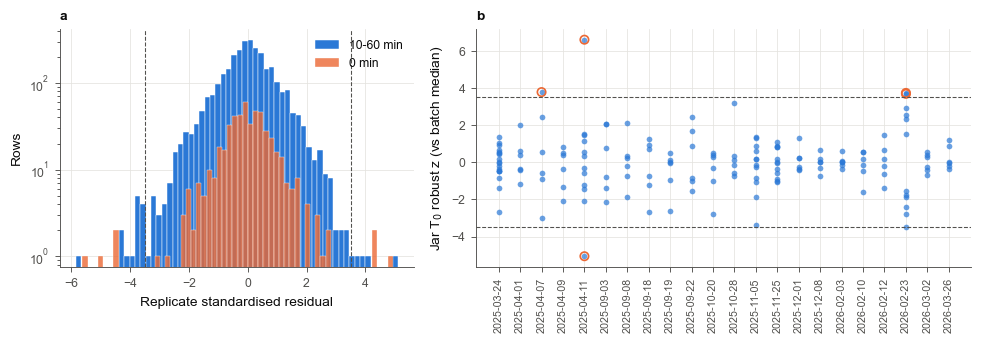

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.2), gridspec_kw={"width_ratios": [1, 1.4]})
ax = axes[0]
ax.hist(df.loc[df["sed"] > 0, "rep_z"], bins=60, color=style.COLORS[0], edgecolor="white", lw=0.3, label="10-60 min")
ax.hist(df.loc[df["sed"] == 0, "rep_z"], bins=60, color=style.COLORS[1], edgecolor="white", lw=0.3, alpha=0.8, label="0 min")
for v in (-3.5, 3.5):
    ax.axvline(v, color=style.INK2, lw=0.7, ls="--")
ax.set_yscale("log")
ax.set_xlabel("Replicate standardised residual")
ax.set_ylabel("Rows")
ax.legend(loc="upper right")
style.panel_label(ax, "a")

ax = axes[1]
ax.scatter(runs["day"], runs["t0_z"], s=14, color=style.COLORS[0], lw=0, alpha=0.7)
m = runs["t0_z"].abs() > 3.5
ax.scatter(runs.loc[m, "day"], runs.loc[m, "t0_z"], s=30, facecolor="none", edgecolor=style.COLORS[1], lw=1.1)
for v in (-3.5, 3.5):
    ax.axhline(v, color=style.INK2, lw=0.7, ls="--")
ax.set_xticks(dates["day"], date_lab, rotation=90, fontsize=7)
ax.set_ylabel("Jar T$_0$ robust z (vs batch median)")
style.panel_label(ax, "b")
fig.tight_layout()
print(style.save(fig, "fig08_outliers"))
plt.show()

## 11. Correlation analysis

In [33]:
X = pd.DataFrame({
    "days": (runs["date"] - runs["date"].min()).dt.days,
    "speed": runs["speed"], "mtime": runs["mtime"], "dose": runs["dose"],
    "log_T0": np.log10(runs["T0"]), "log_T10": np.log10(runs["T10"]),
    "log_T30": np.log10(runs["T30"]), "log_T60": np.log10(runs["T60"]),
    "rem30": runs["rem30"], "rem60": runs["rem60"],
})
pearson = X.corr("pearson")
spearman = X.corr("spearman")
Xw = X - X.groupby(runs["day"]).transform("mean")
Xw = Xw.loc[:, Xw.std() > 1e-9]
within = Xw.corr("pearson")
print("columns with no within-day variation:", sorted(set(X.columns) - set(Xw.columns)))
pearson.round(3).to_csv(STATS / "corr_pearson_pooled.csv")
spearman.round(3).to_csv(STATS / "corr_spearman_pooled.csv")
within.round(3).to_csv(STATS / "corr_pearson_within_day.csv")
spearman.round(2)

columns with no within-day variation: ['days', 'speed']


,days,speed,mtime,dose,log_T0,log_T10,log_T30,log_T60,rem30,rem60
days,1.00,-0.83,0.26,-0.47,0.09,-0.52,-0.58,-0.55,0.34,0.37
speed,-0.83,1.00,-0.19,0.43,0.34,0.76,0.76,0.71,-0.00,-0.06
mtime,0.26,-0.19,1.00,-0.07,-0.12,-0.25,-0.31,-0.32,0.21,0.24
dose,-0.47,0.43,-0.07,1.00,0.12,0.34,0.50,0.56,-0.16,-0.27
log_T0,0.09,0.34,-0.12,0.12,1.00,0.71,0.55,0.48,0.78,0.71
log_T10,-0.52,0.76,-0.25,0.34,0.71,1.00,0.89,0.79,0.33,0.27
log_T30,-0.58,0.76,-0.31,0.50,0.55,0.89,1.00,0.97,0.05,-0.05
log_T60,-0.55,0.71,-0.32,0.56,0.48,0.79,0.97,1.00,-0.03,-0.17
rem30,0.34,-0.00,0.21,-0.16,0.78,0.33,0.05,-0.03,1.00,0.97
rem60,0.37,-0.06,0.24,-0.27,0.71,0.27,-0.05,-0.17,0.97,1.00


In [34]:
within.round(2)

,mtime,dose,log_T0,log_T10,log_T30,log_T60,rem30,rem60
mtime,1.00,0.00,-0.48,-0.40,-0.27,-0.20,0.14,0.11
dose,0.00,1.00,0.17,0.05,0.57,0.69,-0.58,-0.65
log_T0,-0.48,0.17,1.00,0.46,0.33,0.24,-0.12,-0.09
log_T10,-0.40,0.05,0.46,1.00,0.60,0.42,-0.50,-0.38
log_T30,-0.27,0.57,0.33,0.60,1.00,0.93,-0.91,-0.83
log_T60,-0.20,0.69,0.24,0.42,0.93,1.00,-0.89,-0.91
rem30,0.14,-0.58,-0.12,-0.50,-0.91,-0.89,1.00,0.95
rem60,0.11,-0.65,-0.09,-0.38,-0.83,-0.91,0.95,1.00


figures/eda/fig09_correlations.png


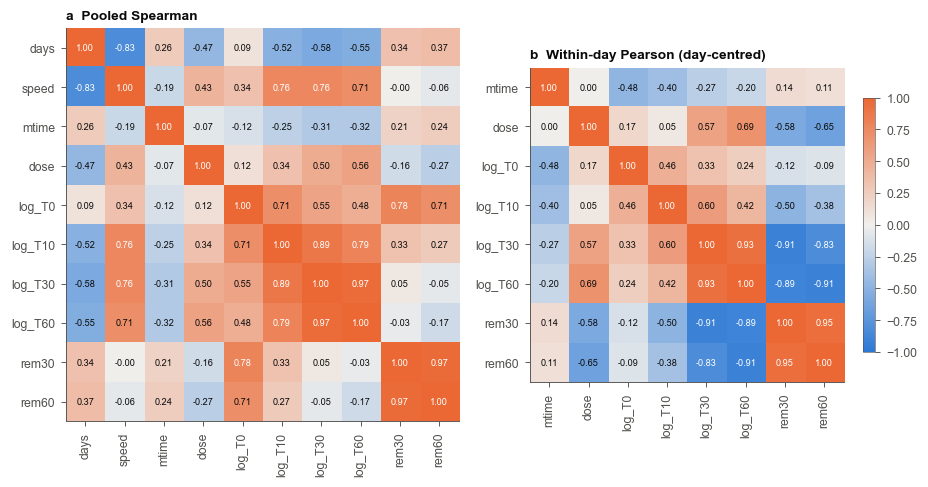

In [35]:
def heat(ax, c, title):
    im = ax.imshow(c.values, cmap=style.DIV, vmin=-1, vmax=1)
    ax.set_xticks(range(len(c)), c.columns, rotation=90)
    ax.set_yticks(range(len(c)), c.index)
    for i in range(len(c)):
        for j in range(len(c)):
            v = c.values[i, j]
            ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=6,
                    color="white" if abs(v) > 0.75 else style.INK)
    ax.grid(False)
    ax.set_title(title, loc="left", fontweight="bold")
    return im

fig, axes = plt.subplots(1, 2, figsize=(11, 5.0), gridspec_kw={"width_ratios": [len(spearman), len(within)]})
heat(axes[0], spearman, "a  Pooled Spearman")
im = heat(axes[1], within, "b  Within-day Pearson (day-centred)")
cb = fig.colorbar(im, ax=axes, shrink=0.6, pad=0.02)
cb.outline.set_linewidth(0.4)
print(style.save(fig, "fig09_correlations"))
plt.show()

Variance inflation among candidate inputs (run level).

In [36]:
def vif(X):
    Z = (X - X.mean()) / X.std()
    out = {}
    for c in Z:
        A = np.c_[np.ones(len(Z)), Z.drop(columns=c)]
        beta, *_ = np.linalg.lstsq(A, Z[c], rcond=None)
        r2 = 1 - ((Z[c] - A @ beta) ** 2).sum() / ((Z[c] - Z[c].mean()) ** 2).sum()
        out[c] = 1 / (1 - r2)
    return pd.Series(out)

pd.DataFrame({
    "VIF all": vif(X[["dose", "log_T0", "speed", "mtime", "days"]]),
    "VIF no days": vif(X[["dose", "log_T0", "speed", "mtime"]]),
}).round(2)

,VIF all,VIF no days
days,5.97,NaN
dose,1.37,1.26
log_T0,1.77,1.24
mtime,1.12,1.11
speed,6.73,1.63


## 12. Variance between and within days

In [37]:
def day_share(y, g):
    k, N = g.nunique(), len(y)
    n_i = g.value_counts()
    means = y.groupby(g).mean()
    ssb = (n_i * (means.reindex(n_i.index) - y.mean()) ** 2).sum()
    ssw = ((y - y.groupby(g).transform("mean")) ** 2).sum()
    msb, msw = ssb / (k - 1), ssw / (N - k)
    n0 = (N - (n_i ** 2).sum() / N) / (k - 1)
    s2b = max((msb - msw) / n0, 0)
    return pd.Series({"eta2": ssb / (ssb + ssw), "ICC": s2b / (s2b + msw)})

vd = {}
for c in ["dose", "speed", "mtime", "log_T0"]:
    vd[c] = day_share(X[c], runs["day"])
for s in SED_TIMES[1:]:
    vd[f"log_T{s}"] = day_share(np.log10(runs[f"T{s}"]), runs["day"])
    vd[f"rem{s}"] = day_share(runs[f"rem{s}"], runs["day"])
vd = pd.DataFrame(vd).T
vd.round(3).to_csv(STATS / "variance_by_day.csv")
vd.round(3)

,eta2,ICC
dose,0.319,0.230
speed,1.000,1.000
mtime,0.702,0.670
log_T0,0.998,0.997
log_T10,0.942,0.937
rem10,0.918,0.910
log_T20,0.905,0.896
rem20,0.905,0.896
log_T30,0.862,0.848
rem30,0.877,0.865


figures/eda/fig10_variance_by_day.png


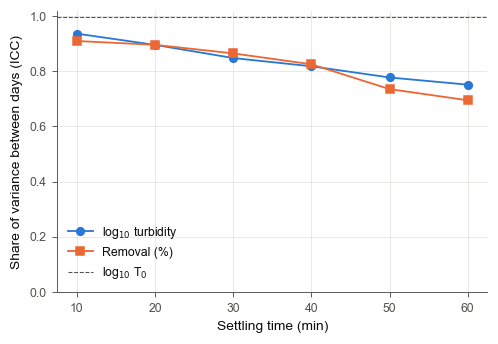

In [38]:
fig, ax = plt.subplots(figsize=(4.6, 3.2))
for i, (pref, lab) in enumerate([("log_T", "log$_{10}$ turbidity"), ("rem", "Removal (%)")]):
    v = [vd.loc[f"{pref}{s}", "ICC"] for s in SED_TIMES[1:]]
    ax.plot(SED_TIMES[1:], v, color=style.COLORS[i], marker=style.MARKERS[i], ms=5, label=lab)
ax.axhline(vd.loc["log_T0", "ICC"], color=style.INK2, lw=0.7, ls="--", label="log$_{10}$ T$_0$")
ax.set_ylim(0, 1.02)
ax.set_xlabel("Settling time (min)")
ax.set_ylabel("Share of variance between days (ICC)")
ax.legend(loc="lower left")
fig.tight_layout()
print(style.save(fig, "fig10_variance_by_day"))
plt.show()

## 13. Feature-space coverage for day-grouped validation

In [39]:
Z = pd.DataFrame({"log_T0": np.log10(runs["T0"]), "dose": runs["dose"]})
Z = (Z - Z.mean()) / Z.std()
rows = []
for day, g in runs.groupby("day"):
    o = runs[runs["day"] != day]
    zin, zout = Z.loc[g.index].values, Z.loc[o.index].values
    nn = np.sqrt(((zin[:, None, :] - zout[None, :, :]) ** 2).sum(-1)).min(1)
    rows.append(dict(
        date=f"{g['date'].iloc[0]:%Y-%m-%d}", runs=len(g),
        T0_outside=int(((g["T0"] < o["T0"].min()) | (g["T0"] > o["T0"].max())).sum()),
        dose_outside=int(((g["dose"] < o["dose"].min()) | (g["dose"] > o["dose"].max())).sum()),
        setting_unseen=not ((o["speed"] == g["speed"].iloc[0]) & (o["mtime"] == g["mtime"].iloc[0])).any(),
        nn_dist_median=np.median(nn), nn_dist_max=nn.max(),
    ))
cover = pd.DataFrame(rows)
cover.round(3).to_csv(STATS / "lodo_coverage.csv", index=False)
print("days whose speed x mixing time is not seen on any other day:", int(cover["setting_unseen"].sum()))
cover.round(2)

days whose speed x mixing time is not seen on any other day: 8


,date,runs,T0_outside,dose_outside,setting_unseen,nn_dist_median,nn_dist_max
0,2025-03-24,18,0,0,True,0.15,0.20
1,2025-04-01,6,0,0,True,0.02,0.03
2,2025-04-07,6,0,0,True,0.05,0.11
3,2025-04-09,6,0,0,False,0.04,0.09
4,2025-04-11,12,0,0,True,0.05,0.15
5,2025-09-03,6,0,0,False,0.28,0.32
6,2025-09-08,6,0,0,True,0.01,0.33
7,2025-09-18,6,0,0,True,0.02,0.07
8,2025-09-19,6,0,0,True,0.03,0.06
9,2025-09-22,6,0,0,False,0.08,0.12


figures/eda/fig11_coverage.png


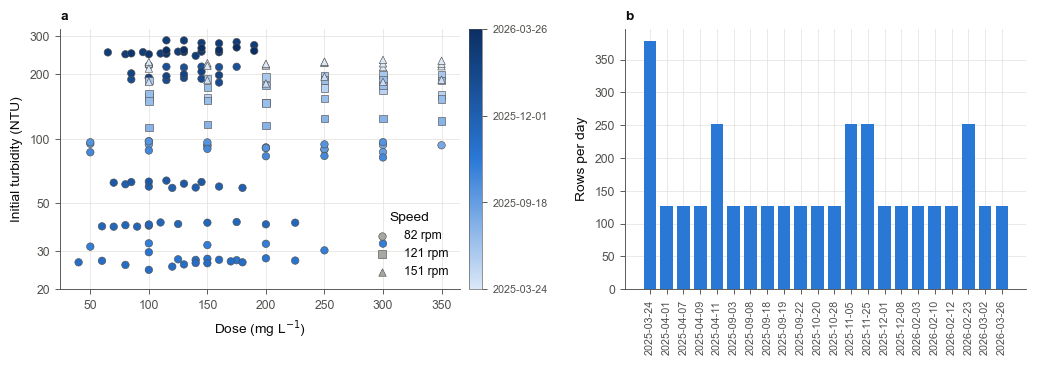

In [40]:
fig, axes = plt.subplots(1, 2, figsize=(9.5, 3.4), gridspec_kw={"width_ratios": [1.2, 1]})
ax = axes[0]
dnorm = Normalize(runs["day"].min(), runs["day"].max())
for i, sp in enumerate(speeds):
    r = runs[runs["speed"] == sp]
    ax.scatter(r["dose"], r["T0"], c=style.SEQ(dnorm(r["day"])), marker=style.MARKERS[i], s=24, lw=0.4,
               edgecolor=style.INK2, label=f"{sp} rpm")
ax.set_yscale("log")
ax.set_yticks([20, 30, 50, 100, 200, 300], labels=["20", "30", "50", "100", "200", "300"])
ax.minorticks_off()
ax.set_xlabel("Dose (mg L$^{-1}$)")
ax.set_ylabel("Initial turbidity (NTU)")
leg = ax.legend(loc="lower right", title="Speed")
for h in leg.legend_handles:
    h.set_facecolor(style.MUTED)
cb = fig.colorbar(plt.cm.ScalarMappable(norm=dnorm, cmap=style.SEQ), ax=ax, pad=0.02)
cb.set_ticks([0, 7, 14, 21], labels=[date_lab.iloc[i] for i in [0, 7, 14, 21]])
cb.ax.tick_params(labelsize=7)
cb.outline.set_linewidth(0.4)
style.panel_label(ax, "a")

ax = axes[1]
size = runs.groupby("day").size()
ax.bar(size.index, size.values * 21, color=style.COLORS[0], width=0.75)
ax.set_xticks(dates["day"], date_lab, rotation=90, fontsize=7)
ax.set_ylabel("Rows per day")
style.panel_label(ax, "b")
fig.tight_layout()
print(style.save(fig, "fig11_coverage"))
plt.show()

## 14. Save processed data

In [41]:
long_cols = ["run", "day", "batch", "date", "speed", "mtime", "dose", "rep_run", "sed", "trial", "turb", "t0_trial", "t0", "removal"]
df[long_cols].to_csv(DATA_PROC / "long.csv", index=False)
cells.to_csv(DATA_PROC / "cells.csv", index=False)
runs.drop(columns=["t0_logratio", "iso_score"]).to_csv(DATA_PROC / "runs.csv", index=False)
for f in ["long.csv", "cells.csv", "runs.csv"]:
    print(f, pd.read_csv(DATA_PROC / f).shape)

long.csv (3528, 14)
cells.csv (1176, 13)
runs.csv (168, 23)


## 15. Key numbers

In [42]:
key = {
    "rows": len(df), "runs": int(df["run"].nunique()), "days": int(df["day"].nunique()),
    "missing_cells": int(raw.isna().sum().sum()), "exact_duplicate_rows": int(raw.duplicated().sum()),
    "repeated_conditions": int(rep.groupby(KEYS).ngroups),
    "replicate_cv_median_0min": round(float(cells.loc[cells["sed"] == 0, "cv"].median()), 2),
    "replicate_cv_median_10_60min": round(float(cells.loc[cells["sed"] > 0, "cv"].median()), 2),
    "replicate_cv_max": round(float(cells["cv"].max()), 2),
    "rep_z_gt_3.5_rows": int((df["rep_z"].abs() > 3.5).sum()),
    "t0_flag_runs": int((runs["t0_z"].abs() > 3.5).sum()),
    "runs_with_rise_any": int(rises["run"].nunique()),
    "runs_with_rise_z_gt_2": int(rises.loc[rises["z>2"], "run"].nunique()),
    "rem60_min": round(float(runs["rem60"].min()), 1), "rem60_median": round(float(runs["rem60"].median()), 1),
    "rem60_max": round(float(runs["rem60"].max()), 1),
    "icc_log_T60": round(float(vd.loc["log_T60", "ICC"]), 3), "icc_rem60": round(float(vd.loc["rem60", "ICC"]), 3),
    "best_dose_interior_days": int((~best["best_at_edge"]).sum()),
    "days_unseen_setting": int(cover["setting_unseen"].sum()),
}
(STATS / "eda_key_numbers.json").write_text(json.dumps(key, indent=2))
pd.Series(key)

rows                            3528.000
runs                             168.000
days                              22.000
missing_cells                      0.000
exact_duplicate_rows               0.000
repeated_conditions                2.000
replicate_cv_median_0min           1.930
replicate_cv_median_10_60min       3.090
replicate_cv_max                  19.690
rep_z_gt_3.5_rows                 26.000
t0_flag_runs                       5.000
runs_with_rise_any                25.000
runs_with_rise_z_gt_2             11.000
rem60_min                         10.700
rem60_median                      77.000
rem60_max                         94.400
icc_log_T60                        0.752
icc_rem60                          0.695
best_dose_interior_days           16.000
days_unseen_setting                8.000
dtype: float64